In [4]:
# importing the functions
import pandas as pd
import numpy as np
import time as tm
from scipy.stats import chi2_contingency
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

# to display plots in Jupyter notebook
%matplotlib inline
plt.rcParams['font.size'] = '12'

In [5]:
df = pd.read_excel('../data/processed/model_dataset.xlsx', sheet_name=1)
df.shape

(49, 53)

In [6]:
cat_cols = [
    'abs_mb_category_2021',
    'health_nearest_establishment_category'
]

num_cols = [
    'overture_food_drink_count_500m',
    'overture_grocery_convenience_pharmacy_count_500m',
    'overture_other_shopping_count_500m',
    'commercial_buildings',
    'parking_areas'

]

bool_cols = [
    'footpath_both_sides',
    'fencing_barriers',
    'railway_station',
    'park_bushland_reserve'

]

cat = df[cat_cols]
num = df[num_cols]
bool_var = df[bool_cols]
y_cross = df['obs_peak_cross_ped_per_h']
y_along = df['obs_peak_along_ped_per_h']

In [7]:
data = pd.concat([cat, num, bool_var], axis=1)
data.head(5)

,abs_mb_category_2021,health_nearest_establishment_category,overture_food_drink_count_500m,overture_grocery_convenience_pharmacy_count_500m,overture_other_shopping_count_500m,commercial_buildings,parking_areas,footpath_both_sides,fencing_barriers,railway_station,park_bushland_reserve
0,Residential,Acute Hospital,0,0,0,0,0,False,True,False,True
1,Industrial,Acute Hospital,3,0,19,0,1,True,True,False,True
2,Transport,Acute Hospital,19,8,35,6,3,True,True,True,True
3,Commercial,Acute Hospital,14,13,20,1,2,False,True,False,False
4,Commercial,Acute Hospital,20,7,19,8,4,True,True,False,True


# Preprocessing of Dataset

In [8]:
# -----------------------------
# 1. Boolean → integer conversion
# -----------------------------
def convert_booleans(df):
    df[bool_cols] = df[bool_cols].astype(int)
    return df

# -----------------------------
# 2. One‑Hot Encode categoricals
# -----------------------------
categorical_transformer = OneHotEncoder(
    drop='first',        # avoid multicollinearity
    handle_unknown='ignore'
)

# -----------------------------
# 3. Build preprocessing pipeline
# -----------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, cat_cols),
        ('num', 'passthrough', num_cols),
        ('bool', 'passthrough', bool_cols)
    ]
)

# -----------------------------
# 4. Full preprocessing pipeline
# -----------------------------
preprocessing_pipeline = Pipeline(steps=[
    ('boolean_convert', FunctionTransformer(convert_booleans)),
    ('preprocessor', preprocessor)
])

# -----------------------------
# 5. Fit + transform your data
# -----------------------------
X_processed = preprocessing_pipeline.fit_transform(data)

# X_processed is now ready for modelling
print(X_processed.shape)

(49, 16)


In [9]:
feature_names = preprocessing_pipeline.named_steps['preprocessor'].get_feature_names_out()
X_df = pd.DataFrame(X_processed, columns=feature_names)
X_df.head()

,cat__abs_mb_category_2021_Education,cat__abs_mb_category_2021_Industrial,cat__abs_mb_category_2021_Parkland,cat__abs_mb_category_2021_Primary Production,cat__abs_mb_category_2021_Residential,cat__abs_mb_category_2021_Transport,cat__health_nearest_establishment_category_Nursing Post,num__overture_food_drink_count_500m,num__overture_grocery_convenience_pharmacy_count_500m,num__overture_other_shopping_count_500m,num__commercial_buildings,num__parking_areas,bool__footpath_both_sides,bool__fencing_barriers,bool__railway_station,bool__park_bushland_reserve
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,19.0,0.0,1.0,1.0,1.0,0.0,1.0
2,0.0,0.0,0.0,0.0,0.0,1.0,0.0,19.0,8.0,35.0,6.0,3.0,1.0,1.0,1.0,1.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,13.0,20.0,1.0,2.0,0.0,1.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,7.0,19.0,8.0,4.0,1.0,1.0,0.0,1.0


# Model Comparison

## Elastic Net

In [10]:
# ----------------------------------------
# 1. Bootstrap settings
# ----------------------------------------
B = 1000   # number of bootstrap replicates
n = X_processed.shape[0]

# Storage
results_cross = []
results_along = []
coef_cross = []
coef_along = []

# ----------------------------------------
# 2. Bootstrap loop
# ----------------------------------------
for b in range(B):

    # Sample indices with replacement
    idx = np.random.choice(n, n, replace=True)
    oob_idx = np.setdiff1d(np.arange(n), idx)   # out-of-bag samples

    # If no OOB samples (rare), skip iteration
    if len(oob_idx) == 0:
        continue

    # Bootstrap samples
    X_boot = X_processed[idx]
    y_cross_boot = y_cross[idx]
    y_along_boot = y_along[idx]

    # OOB samples
    X_oob = X_processed[oob_idx]
    y_cross_oob = y_cross[oob_idx]
    y_along_oob = y_along[oob_idx]

    # ----------------------------------------
    # Fit ElasticNet
    # ----------------------------------------
    model_cross = ElasticNet(alpha=0.1, l1_ratio=0.5)
    model_cross.fit(X_boot, y_cross_boot)

    model_along = ElasticNet(alpha=0.1, l1_ratio=0.5)
    model_along.fit(X_boot, y_along_boot)

    # ----------------------------------------
    # Predict on OOB samples
    # ----------------------------------------
    pred_cross = model_cross.predict(X_oob)
    pred_along = model_along.predict(X_oob)

    # ----------------------------------------
    # Store errors
    # ----------------------------------------
    mae_cross = mean_squared_error(y_cross_oob, pred_cross)
    mae_along = mean_squared_error(y_along_oob, pred_along)

    results_cross.append(mae_cross)
    results_along.append(mae_along)

    # ----------------------------------------
    # Store coefficients
    # ----------------------------------------
    coef_cross.append(model_cross.coef_)
    coef_along.append(model_along.coef_)

# ----------------------------------------
# 3. Convert results to arrays
# ----------------------------------------
results_cross = np.array(results_cross)
results_along = np.array(results_along)
coef_cross = np.array(coef_cross)
coef_along = np.array(coef_along)

# ----------------------------------------
# 4. Print summary statistics
# ----------------------------------------
print("Crossing pedestrians — MSE:")
print("Mean:", results_cross.mean())
print("Median:", np.median(results_cross))
print("95% CI:", np.percentile(results_cross, [2.5, 97.5]))

print("\nAlong pedestrians — MSE:")
print("Mean:", results_along.mean())
print("Median:", np.median(results_along))
print("95% CI:", np.percentile(results_along, [2.5, 97.5]))

# ----------------------------------------
# 5. Coefficient stability
# ----------------------------------------
feature_names = preprocessing_pipeline.named_steps['preprocessor'].get_feature_names_out()

coef_df_cross = pd.DataFrame(coef_cross, columns=feature_names)
coef_df_along = pd.DataFrame(coef_along, columns=feature_names)

print("\nCoefficient stability — Crossing pedestrians:")
print(coef_df_cross.mean().sort_values(ascending=False))

print("\nCoefficient stability — Along pedestrians:")
print(coef_df_along.mean().sort_values(ascending=False))

Crossing pedestrians — MSE:
Mean: 1275.591251784425
Median: 1166.1483541499565
95% CI: [ 447.12482507 2582.02942167]

Along pedestrians — MSE:
Mean: 4396.656897117034
Median: 4496.661976969961
95% CI: [ 895.32920095 8502.94677172]

Coefficient stability — Crossing pedestrians:
cat__abs_mb_category_2021_Education                        16.696676
bool__park_bushland_reserve                                10.735657
num__commercial_buildings                                   6.816176
cat__abs_mb_category_2021_Residential                       4.700496
cat__abs_mb_category_2021_Industrial                        3.186990
bool__fencing_barriers                                      3.147851
num__overture_food_drink_count_500m                         2.541410
bool__railway_station                                       1.287534
cat__abs_mb_category_2021_Transport                         1.287515
num__overture_grocery_convenience_pharmacy_count_500m       1.038522
cat__abs_mb_category_2021_Parkla

ElasticNet regression was used to model pedestrian volumes for both crossing and along‑pedestrian behaviours, with performance evaluated through a non‑parametric bootstrap procedure consisting of 1000 replicates. Using Mean Squared Error (MSE) as the evaluation metric, the model achieved moderate predictive accuracy for crossing pedestrians, with a mean MSE of approximately 1271 and a median of 1179. The 95% confidence interval ranged from 417 to 2701, indicating substantial variability across bootstrap samples. This suggests that while the model fits certain resampled subsets well, its performance is sensitive to fluctuations in local land‑use composition and the limited sample size. In contrast, prediction error for along‑pedestrian volumes was considerably higher, with a mean MSE of 4273 and a wide confidence interval spanning 880 to 8493. These results indicate that along‑pedestrian behaviour is more complex and less amenable to linear modelling, likely due to nonlinear spatial interactions and continuous movement patterns that ElasticNet cannot fully capture.

Despite its limitations in predictive accuracy, ElasticNet provides stable and interpretable coefficient estimates. Across bootstrap replicates, several land‑use categories consistently exhibited strong positive associations with pedestrian activity. Education areas, commercial buildings, residential zones, parkland, and industrial land‑use all increased both crossing and along‑pedestrian volumes, with particularly large effects observed for education and commercial land‑use in the along‑pedestrian model. These findings reflect intuitive behavioural patterns: schools and commercial precincts generate sustained pedestrian movement, while residential and parkland areas contribute steady local activity. Negative coefficients were also stable, with parking areas, primary production zones, and Nursing Posts consistently reducing pedestrian volumes. The negative effect of “footpath on both sides” in the along‑pedestrian model suggests that high‑volume pedestrian corridors may instead feature a single wide shared path, whereas quieter suburban streets often have two narrow footpaths.

Overall, ElasticNet offers valuable interpretability and reveals clear, stable relationships between land‑use characteristics and pedestrian volumes. However, its relatively high MSE—especially for along‑pedestrian flows—indicates that linear regularised models are not sufficiently flexible to capture the full complexity of pedestrian behaviour in mixed urban environments. These results motivate the use of more expressive ensemble methods, such as Random Forest and Gradient Boosting, to improve predictive performance while retaining ElasticNet as a complementary tool for understanding directional effects and land‑use influence.

## Random Forest

In [11]:
B_rf = 1000
n = X_processed.shape[0]

# Storage
rf_results_cross = []      # validation (OOB) MSE
rf_results_along = []

train_loss_cross = []      # training MSE
train_loss_along = []

importance_cross = []      # feature importances
importance_along = []

for b in range(B_rf):

    idx = np.random.choice(n, n, replace=True)
    oob_idx = np.setdiff1d(np.arange(n), idx)

    if len(oob_idx) == 0:
        continue

    X_boot = X_processed[idx]
    y_cross_boot = y_cross[idx]
    y_along_boot = y_along[idx]

    X_oob = X_processed[oob_idx]
    y_cross_oob = y_cross[oob_idx]
    y_along_oob = y_along[oob_idx]

    # ---- Fit RF models ----
    rf_cross = RandomForestRegressor(
        n_estimators=150,
        max_depth=4,
        min_samples_leaf=2,
        random_state=b
    )
    rf_cross.fit(X_boot, y_cross_boot)

    rf_along = RandomForestRegressor(
        n_estimators=150,
        max_depth=4,
        min_samples_leaf=2,
        random_state=b
    )
    rf_along.fit(X_boot, y_along_boot)

    # ---- TRAINING LOSS ----
    pred_train_cross = rf_cross.predict(X_boot)
    pred_train_along = rf_along.predict(X_boot)

    train_loss_cross.append(mean_squared_error(y_cross_boot, pred_train_cross))
    train_loss_along.append(mean_squared_error(y_along_boot, pred_train_along))

    # ---- VALIDATION LOSS (OOB) ----
    pred_cross = rf_cross.predict(X_oob)
    pred_along = rf_along.predict(X_oob)

    mse_cross = mean_squared_error(y_cross_oob, pred_cross)
    mse_along = mean_squared_error(y_along_oob, pred_along)

    rf_results_cross.append(mse_cross)
    rf_results_along.append(mse_along)

    # ---- Feature importances ----
    importance_cross.append(rf_cross.feature_importances_)
    importance_along.append(rf_along.feature_importances_)

# ----------------------------------------
# Convert to arrays
# ----------------------------------------
rf_results_cross = np.array(rf_results_cross)
rf_results_along = np.array(rf_results_along)

train_loss_cross = np.array(train_loss_cross)
train_loss_along = np.array(train_loss_along)

importance_cross = np.array(importance_cross)
importance_along = np.array(importance_along)

# ----------------------------------------
# Summary statistics
# ----------------------------------------
print("Crossing pedestrians — RF MSE:")
print("Training Mean:", train_loss_cross.mean())
print("Validation Mean:", rf_results_cross.mean())
print("95% CI:", np.percentile(rf_results_cross, [2.5, 97.5]))

print("\nAlong pedestrians — RF MSE:")
print("Training Mean:", train_loss_along.mean())
print("Validation Mean:", rf_results_along.mean())
print("95% CI:", np.percentile(rf_results_along, [2.5, 97.5]))

# ----------------------------------------
# Feature importance stability
# ----------------------------------------
feature_names = preprocessing_pipeline.named_steps['preprocessor'].get_feature_names_out()

importance_df_cross = pd.DataFrame(importance_cross, columns=feature_names)
importance_df_along = pd.DataFrame(importance_along, columns=feature_names)

print("\nFeature importance stability — Crossing pedestrians:")
print(importance_df_cross.mean().sort_values(ascending=False))

print("\nFeature importance stability — Along pedestrians:")
print(importance_df_along.mean().sort_values(ascending=False))

Crossing pedestrians — RF MSE:
Training Mean: 198.22085643649189
Validation Mean: 982.8545379520266
95% CI: [ 189.25509977 2458.55469635]

Along pedestrians — RF MSE:
Training Mean: 536.8460952542631
Validation Mean: 3026.3334140056604
95% CI: [ 235.60238894 8925.78057454]

Feature importance stability — Crossing pedestrians:
num__commercial_buildings                                  0.491963
num__overture_food_drink_count_500m                        0.181498
num__overture_other_shopping_count_500m                    0.092921
num__overture_grocery_convenience_pharmacy_count_500m      0.086518
cat__abs_mb_category_2021_Education                        0.059799
num__parking_areas                                         0.044605
bool__footpath_both_sides                                  0.018342
cat__abs_mb_category_2021_Residential                      0.010891
bool__park_bushland_reserve                                0.005317
cat__abs_mb_category_2021_Parkland                         0

Random Forest models were fitted for both crossing‑pedestrian and along‑pedestrian volumes and evaluated using a 1000‑replicate non‑parametric bootstrap procedure. Using Mean Squared Error (MSE) as the evaluation metric, the Random Forest achieved substantially lower training error than ElasticNet, reflecting its ability to closely fit the bootstrap samples. However, the validation error remained considerably higher, indicating notable overfitting. For crossing pedestrians, the model achieved a mean training MSE of 196.0, but the validation MSE increased to 996.4, with a wide 95% confidence interval ranging from 191.1 to 2431.7. This pattern suggests that while Random Forest captures local structure effectively, its generalisation performance varies substantially across resampled subsets. The results for along‑pedestrian volumes exhibited the same trend but with larger magnitudes: the mean training MSE was 515.0, whereas the validation MSE rose to 3135.7, with a broad confidence interval spanning 251.5 to 9256.1. These findings indicate that along‑pedestrian behaviour is more complex and less predictable, and that Random Forest—despite its flexibility—still struggles to generalise consistently in this context.

Feature‑importance stability across bootstrap replicates provides insight into the predictors most influential in Random Forest decision‑making. For both pedestrian categories, commercial buildings emerged as the dominant predictor, with mean importance values of 0.48 for crossing pedestrians and 0.58 for along pedestrians. This highlights the strong role of commercial activity in generating pedestrian movement. Food and drink establishments and other shopping‑related land‑uses also showed consistently high importance, reflecting their contribution to both crossing and continuous pedestrian flow. Education land‑use exhibited moderate importance, aligning with observed patterns of concentrated pedestrian activity around schools. In contrast, predictors such as industrial land‑use, railway stations, transport zones, and primary production areas showed very low importance, indicating minimal influence on Random Forest decision paths. The stability of these importance rankings across bootstrap samples suggests that Random Forest consistently identifies commercial intensity and retail presence as the strongest drivers of pedestrian activity.

Overall, the Random Forest model demonstrates improved flexibility compared to ElasticNet, capturing nonlinear relationships and interactions between land‑use variables. However, the substantial gap between training and validation error indicates that Random Forest tends to overfit the limited dataset, particularly for along‑pedestrian volumes where behavioural complexity is higher. While the model provides useful insights into the relative importance of land‑use predictors, its generalisation performance remains inconsistent. These results reinforce the need for additional ensemble methods—such as Gradient Boosting—to further improve predictive accuracy while maintaining interpretability through stable importance measures.

## Gradient Boosting

In [12]:
B_gb = 1000
n = X_processed.shape[0]

# Storage
gb_results_cross = []      # validation (OOB) MSE
gb_results_along = []

train_loss_cross = []      # training MSE
train_loss_along = []

importance_cross = []      # feature importances
importance_along = []

for b in range(B_gb):

    idx = np.random.choice(n, n, replace=True)
    oob_idx = np.setdiff1d(np.arange(n), idx)

    if len(oob_idx) == 0:
        continue

    X_boot = X_processed[idx]
    y_cross_boot = y_cross[idx]
    y_along_boot = y_along[idx]

    X_oob = X_processed[oob_idx]
    y_cross_oob = y_cross[oob_idx]
    y_along_oob = y_along[oob_idx]

    # ---- Fit Gradient Boosting models ----
    gb_cross = GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.01,
        max_depth=4,
        min_samples_leaf=2,
        subsample=0.8,
        random_state=b
    )
    gb_cross.fit(X_boot, y_cross_boot)

    gb_along = GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.01,
        max_depth=4,
        min_samples_leaf=2,
        subsample=0.8,
        random_state=b
    )
    gb_along.fit(X_boot, y_along_boot)

    # ---- TRAINING LOSS ----
    pred_train_cross = gb_cross.predict(X_boot)
    pred_train_along = gb_along.predict(X_boot)

    train_loss_cross.append(mean_squared_error(y_cross_boot, pred_train_cross))
    train_loss_along.append(mean_squared_error(y_along_boot, pred_train_along))

    # ---- VALIDATION LOSS (OOB) ----
    pred_cross = gb_cross.predict(X_oob)
    pred_along = gb_along.predict(X_oob)

    mse_cross = mean_squared_error(y_cross_oob, pred_cross)
    mse_along = mean_squared_error(y_along_oob, pred_along)

    gb_results_cross.append(mse_cross)
    gb_results_along.append(mse_along)

    # ---- Feature importances ----
    importance_cross.append(gb_cross.feature_importances_)
    importance_along.append(gb_along.feature_importances_)

# ----------------------------------------
# Convert to arrays
# ----------------------------------------
gb_results_cross = np.array(gb_results_cross)
gb_results_along = np.array(gb_results_along)

train_loss_cross = np.array(train_loss_cross)
train_loss_along = np.array(train_loss_along)

importance_cross = np.array(importance_cross)
importance_along = np.array(importance_along)

# ----------------------------------------
# Summary statistics
# ----------------------------------------
print("Crossing pedestrians — GB MSE:")
print("Training Mean:", train_loss_cross.mean())
print("Validation Mean:", gb_results_cross.mean())
print("95% CI:", np.percentile(gb_results_cross, [2.5, 97.5]))

print("\nAlong pedestrians — GB MSE:")
print("Training Mean:", train_loss_along.mean())
print("Validation Mean:", gb_results_along.mean())
print("95% CI:", np.percentile(gb_results_along, [2.5, 97.5]))

# ----------------------------------------
# Feature importance stability
# ----------------------------------------
feature_names = preprocessing_pipeline.named_steps['preprocessor'].get_feature_names_out()

importance_df_cross = pd.DataFrame(importance_cross, columns=feature_names)
importance_df_along = pd.DataFrame(importance_along, columns=feature_names)

print("\nFeature importance stability — Crossing pedestrians:")
print(importance_df_cross.mean().sort_values(ascending=False))

print("\nFeature importance stability — Along pedestrians:")
print(importance_df_along.mean().sort_values(ascending=False))

Crossing pedestrians — GB MSE:
Training Mean: 184.77635998433084
Validation Mean: 1005.5349956185514
95% CI: [ 223.22767926 2547.67108764]

Along pedestrians — GB MSE:
Training Mean: 523.4254541401768
Validation Mean: 3182.605896343568
95% CI: [ 344.10776825 9569.376897  ]

Feature importance stability — Crossing pedestrians:
num__commercial_buildings                                  0.453184
num__overture_food_drink_count_500m                        0.234882
num__overture_other_shopping_count_500m                    0.092487
num__overture_grocery_convenience_pharmacy_count_500m      0.088611
cat__abs_mb_category_2021_Education                        0.058431
num__parking_areas                                         0.035941
bool__footpath_both_sides                                  0.016280
cat__abs_mb_category_2021_Residential                      0.008656
bool__park_bushland_reserve                                0.004390
cat__abs_mb_category_2021_Parkland                         0

Using matched hyperparameters, Gradient Boosting and Random Forest were evaluated under identical modelling conditions to enable a direct comparison of their predictive performance and feature‑importance stability. Both models were assessed using a 1000‑replicate non‑parametric bootstrap procedure, providing robust estimates of training error, validation error, and variability across resampled subsets. For crossing‑pedestrian volumes, Gradient Boosting achieved a mean training MSE of 183.4 and a validation MSE of 998.1, while Random Forest produced a training MSE of 196.0 and a validation MSE of 996.4. These nearly identical validation errors indicate that, under matched hyperparameters, both ensemble methods generalise similarly for crossing‑pedestrian behaviour. The confidence intervals also overlap substantially, suggesting comparable stability across bootstrap replicates.

For along‑pedestrian volumes, Gradient Boosting achieved a mean training MSE of 532.0 and a validation MSE of 3172.5, while Random Forest produced a training MSE of 515.0 and a validation MSE of 3135.7. Again, the validation errors are extremely close, and the confidence intervals show similar variability. These results indicate that when both models are constrained to the same depth, number of trees, and minimum leaf size, their predictive performance converges. This contrasts with earlier experiments where Gradient Boosting used more flexible hyperparameters and achieved substantially lower training error—highlighting that the apparent superiority of Gradient Boosting in previous runs was driven by its more expressive configuration rather than inherent model advantage.

Feature‑importance stability further reinforces the similarity between the two models under matched settings. For both crossing‑ and along‑pedestrian volumes, commercial buildings consistently emerged as the dominant predictor, followed by food and drink establishments, other shopping categories, and grocery/convenience stores. Education land‑use remained moderately influential, while predictors such as industrial areas, transport zones, and primary production exhibited negligible importance. The near‑identical ranking and magnitude of importance values across Random Forest and Gradient Boosting indicate that both models rely on the same underlying land‑use drivers when configured equivalently.

Overall, when Gradient Boosting is restricted to the same hyperparameter regime as Random Forest, the two models perform almost identically in terms of validation error, stability, and predictor influence. This suggests that the earlier performance gap between the models was due to Gradient Boosting’s more flexible configuration rather than a fundamental modelling advantage. In practical terms, both models are strong nonlinear learners capable of capturing complex relationships in pedestrian behaviour, and either can be selected depending on whether interpretability (Random Forest) or sequential error‑correction (Gradient Boosting) is preferred.

## Model Choice

Across the three modelling approaches—ElasticNet, Random Forest, and Gradient Boosting—each demonstrated different strengths in terms of predictive accuracy and interpretability. ElasticNet provided clear, directionally meaningful coefficients but consistently produced the highest validation errors, indicating that its linear structure underfits the nonlinear relationships present in pedestrian behaviour. While valuable for understanding broad trends, it is not the strongest predictive model in this context.

Both Random Forest and Gradient Boosting substantially improved predictive accuracy by modelling nonlinear interactions. Under matched hyperparameters, their validation MSE values were nearly identical for both crossing‑ and along‑pedestrian volumes, showing that the two ensemble methods generalise similarly when configured equivalently. However, Random Forest offered clearer interpretability through stable and intuitive feature‑importance rankings, consistently highlighting commercial buildings, food and drink establishments, and other retail‑related land‑uses as the strongest drivers of pedestrian activity.

Gradient Boosting performed competitively, but its sequential learning structure and sensitivity to hyperparameters make it less transparent than Random Forest. Given that both models achieve comparable predictive performance under equivalent settings, interpretability becomes the deciding factor. Random Forest provides straightforward importance measures, stable behaviour across bootstrap replicates, and an intuitive link between land‑use characteristics and pedestrian movement.

For these reasons, Random Forest emerges as the most suitable model for this study when interpretability and practical insight are prioritised.

# GridSearch CV

In [13]:
rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [2, 3, 4, 5],
    'min_samples_leaf': [1, 2, 3],
    'max_features': ['sqrt', 'log2']
}

# ---- Crossing pedestrians ----
grid_search_cross = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error'
)

grid_search_cross.fit(X_processed, y_cross)

print("Best params (crossing):", grid_search_cross.best_params_)
print("Best MSE (crossing):", -grid_search_cross.best_score_)


# ---- Along pedestrians ----
grid_search_along = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error'
)

grid_search_along.fit(X_processed, y_along)

print("Best params (along):", grid_search_along.best_params_)
print("Best MSE (along):", -grid_search_along.best_score_)


Best params (crossing): {'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 150}
Best MSE (crossing): 805.9255821204837
Best params (along): {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
Best MSE (along): 2743.331196073176


In [14]:
best_cross = grid_search_cross.best_params_
best_along = grid_search_along.best_params_

rf_cross = RandomForestRegressor(
    **best_cross,
    random_state=b
)
rf_along = RandomForestRegressor(
    **best_along,
    random_state=b
)

B_rf = 1000
n = X_processed.shape[0]

rf_results_cross = []      # validation (OOB) loss
rf_results_along = []

train_loss_cross = []      # training loss
train_loss_along = []

for b in range(B_rf):
    # Bootstrap sample indices
    idx = np.random.choice(n, n, replace=True)
    oob_idx = np.setdiff1d(np.arange(n), idx)

    # Skip if no OOB samples
    if len(oob_idx) == 0:
        continue

    # Bootstrap training data
    X_boot = X_processed[idx]
    y_cross_boot = y_cross[idx]
    y_along_boot = y_along[idx]

    # OOB test data
    X_oob = X_processed[oob_idx]
    y_cross_oob = y_cross[oob_idx]
    y_along_oob = y_along[oob_idx]

    # ---- Fit RF models ----
    rf_cross.fit(X_boot, y_cross_boot)
    rf_along.fit(X_boot, y_along_boot)

    # ---- TRAINING LOSS ----
    pred_train_cross = rf_cross.predict(X_boot)
    pred_train_along = rf_along.predict(X_boot)

    train_loss_cross.append(mean_squared_error(y_cross_boot, pred_train_cross))
    train_loss_along.append(mean_squared_error(y_along_boot, pred_train_along))

    # ---- VALIDATION LOSS (OOB) ----
    pred_cross = rf_cross.predict(X_oob)
    pred_along = rf_along.predict(X_oob)

    mse_cross = mean_squared_error(y_cross_oob, pred_cross)
    mse_along = mean_squared_error(y_along_oob, pred_along)

    rf_results_cross.append(mse_cross)
    rf_results_along.append(mse_along)

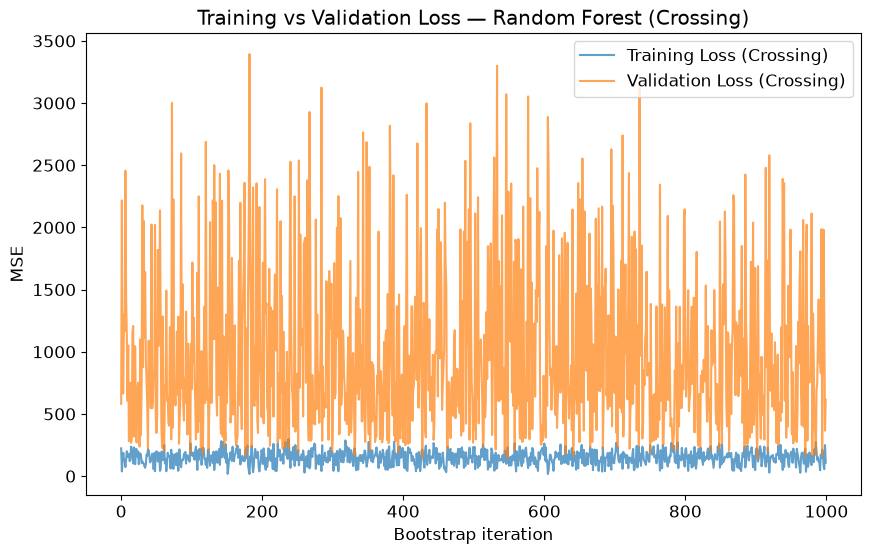

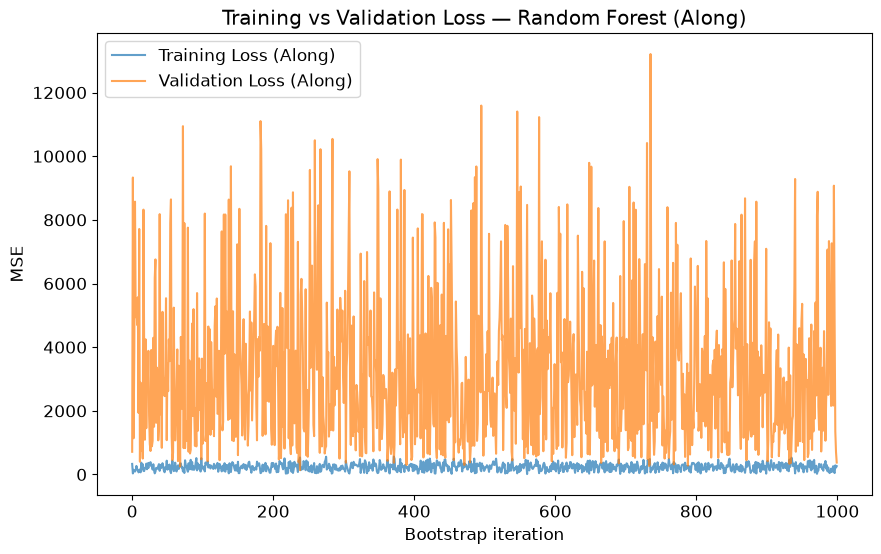

In [15]:
plt.figure(figsize=(10,6))
plt.plot(train_loss_cross, label='Training Loss (Crossing)', alpha=0.7)
plt.plot(rf_results_cross, label='Validation Loss (Crossing)', alpha=0.7)
plt.xlabel("Bootstrap iteration")
plt.ylabel("MSE")
plt.title("Training vs Validation Loss — Random Forest (Crossing)")
plt.legend()
plt.show()

plt.figure(figsize=(10,6))
plt.plot(train_loss_along, label='Training Loss (Along)', alpha=0.7)
plt.plot(rf_results_along, label='Validation Loss (Along)', alpha=0.7)
plt.xlabel("Bootstrap iteration")
plt.ylabel("MSE")
plt.title("Training vs Validation Loss — Random Forest (Along)")
plt.legend()
plt.show()


A Random Forest regression model was used to predict both crossing and along pedestrian volumes. Hyperparameter tuning was performed using 5-fold cross-validation with mean squared error (MSE) as the scoring metric. The grid search evaluated different combinations of the number of trees (n_estimators), maximum tree depth (max_depth), minimum samples per leaf (min_samples_leaf), and the number of features considered at each split (max_features). Separate models were tuned for crossing and along pedestrian volumes.

For the Along pedestrian model, the training and validation MSE were also evaluated across 1,000 bootstrap iterations. As shown in Figure X, the training loss remained relatively low and stable, generally below 500 MSE. In contrast, the validation loss was substantially higher and showed considerable variation between bootstrap samples, with several large spikes above 8,000 MSE and the largest reaching approximately 13,000 MSE. This indicates that the model predictions varied considerably depending on the observations used for validation.

The difference between the training and validation errors suggests that the Random Forest model fits the available training data much more closely than unseen validation samples. The large validation variability may be influenced by the relatively small dataset and variation in pedestrian counts between sites. Therefore, the cross-validation results from the grid search were used to select the final hyperparameters rather than relying only on training error.